In [ ]:
# ===== Standard library =====
import csv
import datetime
import glob
import itertools
import os
import pickle
import random
import re
from collections import Counter
from datetime import timedelta
from pathlib import Path

# ===== Numerical & data handling =====
import numpy as np
import pandas as pd
import polars as pl
from numpy.random import default_rng

# ===== Visualization =====
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Rectangle, ConnectionPatch
from matplotlib.ticker import FuncFormatter

# ===== Scikit-learn =====
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, auc, average_precision_score,
    balanced_accuracy_score, classification_report, confusion_matrix,
    f1_score, precision_recall_curve, precision_recall_fscore_support,
    precision_score, recall_score, roc_auc_score
)
from sklearn.model_selection import GroupShuffleSplit, KFold, train_test_split
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler
from sklearn.utils import shuffle
from sklearn.utils.class_weight import compute_class_weight

# ===== Imbalanced-learn =====
from imblearn.under_sampling import RandomUnderSampler

# ===== TensorFlow / Keras =====
import tensorflow as tf
from keras.models import load_model
from keras.utils import to_categorical
from tcn import TCN
from tensorflow import keras
from tensorflow.keras import backend as K
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.layers import (
    Activation, Add, BatchNormalization, Concatenate, Conv1D, Dense,
    Dropout, Embedding, Flatten, GlobalAveragePooling1D, Input, MaxPooling1D
)
from tensorflow.keras.models import Model, Sequential

# ===== Machine learning / optimization =====
import joblib
import lightgbm as lgb
import optuna
import shap
from joblib import load, dump
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, Subset

# PyTorch Geometric
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader
from torch_geometric.nn import GATv2Conv, global_max_pool
from torch_geometric.nn.aggr import MinAggregation

from torch_focalloss import BinaryFocalLoss, MultiClassFocalLoss
from ts2vg import NaturalVG

## Functions

In [ ]:
# convert all sublists to arrays
def flatten(subject):
    array_data = [np.array(x) for x in subject]  
    flattened_data = np.concatenate(array_data, axis=0)
    return flattened_data

In [ ]:
class NVGDataset(Dataset):

    def __init__(self, X, A, y):

        self.X = X
        self.A = np.asarray(A, dtype=np.uint8)
        self.y = np.asarray(y, dtype=np.float32)

        assert self.X.shape[1:] == (25, 1)
        assert self.A.shape[1:] == (79,)
        assert len(self.X) == len(self.A) == len(self.y)

        self.T = self.X.shape[1]

        self.time = np.linspace(
            0, 1, self.T, dtype=np.float32
        )

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):

        values = np.asarray(self.X[idx, :, 0], dtype=np.float32)
        
        A = np.unpackbits(
            self.A[idx],
            count=625
        ).reshape(25, 25)

        A_with_self = A.copy()
        np.fill_diagonal(A_with_self, 1)

        degree = (
            (A_with_self > 0).sum(axis=1)
            / self.T
        ).astype(np.float32)

        node_features = np.stack(
            [
                values,
                self.time,
                degree
            ],
            axis=1
        ).astype(np.float32)

        A_edges = A.copy()
        np.fill_diagonal(A_edges, 0)

        src, dst = np.nonzero(A_edges)

        edge_index = torch.tensor(
            np.stack([src, dst]),
            dtype=torch.long
        )


        dy = values[src] - values[dst]
        dt = self.time[src] - self.time[dst]

        distances = np.sqrt(
            dy ** 2 + dt ** 2
        ).astype(np.float32)

        edge_attr = torch.from_numpy(
            distances[:, None])

        label = int(np.argmax(self.y[idx]))

        return Data(
            x=torch.from_numpy(node_features),
            edge_index=edge_index,
            edge_attr=edge_attr,
            y=torch.tensor(label, dtype=torch.long)
        )




def create_nvg_dataset(
    X,
    A,
    y,
    batch_size=2048,
    shuffle=True,
    rand_seed = 42
):

    dataset = NVGDataset(X=X, A=A, y=y)

    generator = torch.Generator()
    generator.manual_seed(rand_seed)

    loader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        num_workers=0,
        pin_memory=False,
        persistent_workers=False,
        generator=generator
    )


    return loader

class NVG_GATv2(nn.Module):

    def __init__(self, num_classes=4):
        super().__init__()

        self.node_dense = nn.Linear(3, 64)
        self.edge_dense = nn.Linear(1, 8)

        self.gatv2conv1 = GATv2Conv(
            in_channels=64,
            out_channels=8,
            heads=6,
            concat=True,
            edge_dim=8,
            add_self_loops=True,
            fill_value=0.0
        )

        self.bn1 = nn.BatchNorm1d(48)

        self.gatv2conv2 = GATv2Conv(
            in_channels=48,
            out_channels=8,
            heads=6,
            concat=True,
            edge_dim=8,
            add_self_loops=True,
            fill_value=0.0
        )

        self.bn2 = nn.BatchNorm1d(48)

        self.classifier = nn.Linear(48, num_classes)

    def forward(self, data):

        x = data.x
        edge_index = data.edge_index
        edge_attr = data.edge_attr
        batch = data.batch

        # Node and edge projections
        x = F.relu(self.node_dense(x))
        edge_attr = F.relu(self.edge_dense(edge_attr))

        # GATv2 block 1
        x = self.gatv2conv1(x, edge_index, edge_attr=edge_attr)
        x = self.bn1(x)
        x = F.elu(x)

        # GATv2 block 2
        x = self.gatv2conv2(x, edge_index, edge_attr=edge_attr)
        x = self.bn2(x)
        x = F.elu(x)

        # Max graph pooling
        x = global_max_pool(x, batch)

        # 4-class logits
        return self.classifier(x)

## Read data and assing age groups

In [ ]:
X_feat_test, Y_test = load("Data/ML_Test.joblib")
X_DL_test, Y_test = load("Data/DL_Test.joblib")
X_DL_Avg = np.load("/GAT/data/A_nvg_OS_Test.npy", mmap_mode="r")
Y_exact, Y_test_ex = load("Data/DL_Test_Misclass.joblib")

In [ ]:
comparison = flatten(Y_test_ex) == flatten(Y_test)
any_false = (comparison == False).any()

In [6]:
np.array_equal(flatten(Y_test_ex), flatten(Y_test))

True

In [7]:
assert len(flatten(X_DL_test)) == len(flatten(Y_test)) == len(X_DL_Avg)

In [ ]:
# ensures reproducability
seed_value= 42  
os.environ['PYTHONHASHSEED']=str(seed_value)
random.seed(seed_value)
np.random.seed(seed_value)


# flattens the arrays of single subjects into one array of shape (X,25,2)
X_test_fold = flatten(X_DL_test)
# flattens the arrays of single subjects into one array of shape (X,1)
Y_test_fold = flatten(Y_test)
Y_exact = flatten(Y_exact)

Y_test_rs = to_categorical(Y_test_fold)

Y_test_fold_cat = Y_test_fold.reshape(-1)
Y_test_cat_pt = np.eye(4, dtype=np.float32)[Y_test_fold_cat] 

# converts train, val, and test data into tensors
X_test_t = tf.convert_to_tensor(X_test_fold, dtype=tf.float32)
Y_test_t = tf.convert_to_tensor(Y_test_rs, dtype=tf.int32)


##### Data for static #####
X_test_feat_all = flatten(X_feat_test)

Y_test_all = Y_test_fold.reshape(-1)

In [11]:
print(X_test_t.shape)
print(Y_test_t.shape)
print(X_test_fold.shape)
print(Y_test_fold.shape)
print(X_test_feat_all.shape)
print(Y_test_all.shape)
print(Y_test_cat_pt.shape)

(3552429, 25, 1)
(3552429, 4)
(3552429, 25, 1)
(3552429, 1)
(3552429, 83)
(3552429,)
(3552429, 4)


In [12]:
np.bincount(Y_test_all)

array([1199210,  340979,  626318, 1385922])

## LightGBM

In [ ]:
a = [
 'GlucoseCGM', 'diff_5', 'diff_10', 'diff_20', 'diff_40', 'GlucoseCGM_mean_30min', 'GlucoseCGM_std_30min', 'GlucoseCGM_min_30min', 'GlucoseCGM_max_30min', 'n_30min', 'time_below70_30min', 'time_above200_30min', 'diff_30min', 'slope_30min', 'GlucoseCGM_mean_1hr',
 'GlucoseCGM_std_1hr', 'GlucoseCGM_min_1hr', 'GlucoseCGM_max_1hr', 'n_1hr', 'time_below70_1hr', 'time_above200_1hr', 'diff_1hr', 'slope_1hr', 'GlucoseCGM_mean_2hr', 'GlucoseCGM_std_2hr', 'GlucoseCGM_min_2hr', 'GlucoseCGM_max_2hr', 'n_2hr', 'time_below70_2hr', 'time_above200_2hr', 'diff_2hr', 'slope_2hr', 'GlucoseCGM_mean_4hr', 'GlucoseCGM_std_4hr',  'GlucoseCGM_min_4hr', 'GlucoseCGM_max_4hr', 'n_4hr', 'time_below70_4hr',
 'time_above200_4hr', 'diff_4hr', 'slope_4hr', 'GlucoseCGM_mean_8hr', 'GlucoseCGM_std_8hr', 'GlucoseCGM_min_8hr', 'GlucoseCGM_max_8hr', 'n_8hr', 'time_below70_8hr',
 'time_above200_8hr', 'diff_8hr', 'slope_8hr', 'GlucoseCGM_mean_24hr', 'GlucoseCGM_std_24hr', 'GlucoseCGM_min_24hr', 'GlucoseCGM_max_24hr', 'n_24hr', 'time_below70_24hr',  'time_above200_24hr',  'diff_24hr', 'slope_24hr', 'hypo_points_30m', 'avg_event_duration_min_30m', 'min_since_last_event_30m', 'hypo_points_1h', 'avg_event_duration_min_1h', 'min_since_last_event_1h', 'hypo_points_2h', 'avg_event_duration_min_2h', 'min_since_last_event_2h', 'hypo_points_4h', 'avg_event_duration_min_4h', 'min_since_last_event_4h',  'hypo_points_24h', 'avg_event_duration_min_24h', 'min_since_last_event_24h', 'hour', 'minute', 'dayofweek', 'valid_30min', 'valid_1hr', 'valid_2hr', 'valid_4hr',  'valid_8hr', 'valid_24hr',]

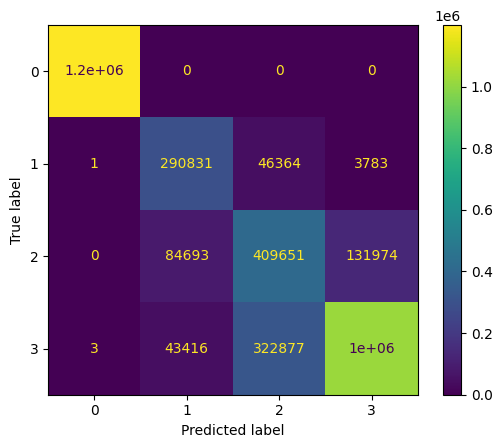


Classification Report:
               precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000   1199210
           1     0.6942    0.8529    0.7654    340979
           2     0.5259    0.6541    0.5830    626318
           3     0.8825    0.7357    0.8024   1385922

    accuracy                         0.8218   3552429
   macro avg     0.7757    0.8107    0.7877   3552429
weighted avg     0.8412    0.8218    0.8269   3552429



In [ ]:
model_lbgm= joblib.load('Saved_Models/model_lgm.pkl')
X_test_feat_all_df = pd.DataFrame(X_test_feat_all, columns=a)

y_pred_labels_lbgm = model_lbgm.predict(X_test_feat_all_df)
y_pred_prob_lbgm = model_lbgm.predict_proba(X_test_feat_all_df)
ConfusionMatrixDisplay.from_predictions(Y_test_all, y_pred_labels_lbgm)
plt.show()

print("\nClassification Report:\n", classification_report(Y_test_all, y_pred_labels_lbgm, digits=4))

## TCN

In [ ]:
X_train, Y_train = load("Data/DataTrain_Multiclass_DL.joblib")

# ensures reproducability
seed_value= 42  
os.environ['PYTHONHASHSEED']=str(seed_value)
random.seed(seed_value)
np.random.seed(seed_value)


# assuming X_data and Y_data are lists (or arrays) where each entry corresponds to one subject
subject_indices = list(range(len(Y_train)))


# split into temp and test (20%)
train_idx, abl_idx = train_test_split(subject_indices, test_size=0.05, shuffle=True, random_state=seed_value)


X_train_fold = [X_train[i] for i in train_idx]
Y_train_fold = [Y_train[i] for i in train_idx]


print(len(train_idx))

# flattens the arrays of single subjects into one array of shape (X,25,2)
Y_train_fold  =flatten(Y_train_fold)
Y_train_fold= Y_train_fold.reshape(-1)

# flattens the arrays of single subjects into one array of shape (X,1)
X_train_fold = flatten(X_train_fold)


print(X_train_fold.shape)

BATCH_SIZE =  256  
BUFFER_SIZE = min(len(X_train_fold), 10_000)
SEED = 42

Y_train_rs = to_categorical(Y_train_fold)
Y_test_rs = to_categorical(Y_test_fold)
# for class weights 
Y_train_weights = Y_train_fold.reshape(-1).astype('int32')

# converts train, val, and test data into tensors
X_train_t = tf.convert_to_tensor(X_train_fold, dtype=tf.float32)
Y_train_t = tf.convert_to_tensor(Y_train_rs, dtype=tf.int32)


# shuffles train data and applies batch size 
train_ds_t = tf.data.Dataset.from_tensor_slices((X_train_t, Y_train_t))
train_ds = train_ds_t.shuffle(BUFFER_SIZE, seed=SEED).batch(BATCH_SIZE).prefetch(1)

Y_train_all = Y_train_fold.reshape(-1)

1906
(12891361, 25, 1)


111014/111014 ━━━━━━━━━━━━━━━━━━━━ 640s 6ms/step


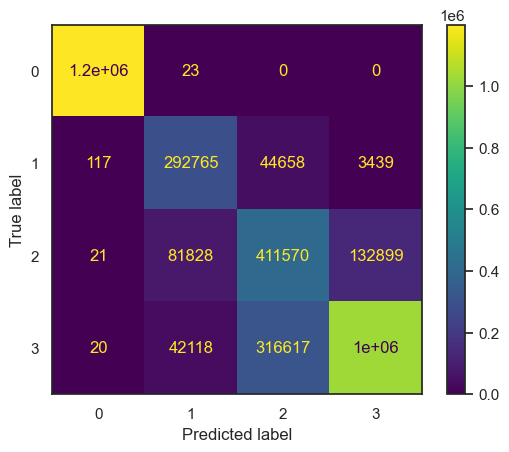

              precision    recall  f1-score   support

           0     0.9999    1.0000    0.9999   1199210
           1     0.7025    0.8586    0.7728    340979
           2     0.5325    0.6571    0.5883    626318
           3     0.8828    0.7411    0.8058   1385922

    accuracy                         0.8250   3552429
   macro avg     0.7794    0.8142    0.7917   3552429
weighted avg     0.8433    0.8250    0.8298   3552429



In [ ]:
model_tcn = load_model("Saved_Models/TCN_model_OS.keras")


sns.set_theme(style="white")
# evaluates the model and plots the confusion matrix
predictions_tcn = model_tcn.predict(X_test_t)

y_pred_tcn = np.argmax(predictions_tcn, axis=1) 
    

final_preds_tcn = y_pred_tcn

y_true_labels_tcn = np.argmax(Y_test_t, axis=1)
ConfusionMatrixDisplay.from_predictions(y_true_labels_tcn, final_preds_tcn)
plt.show()

report_tcn = classification_report(y_true_labels_tcn, final_preds_tcn, digits=4)
print(report_tcn)

## TCN MHAL

111014/111014 ━━━━━━━━━━━━━━━━━━━━ 659s 6ms/step


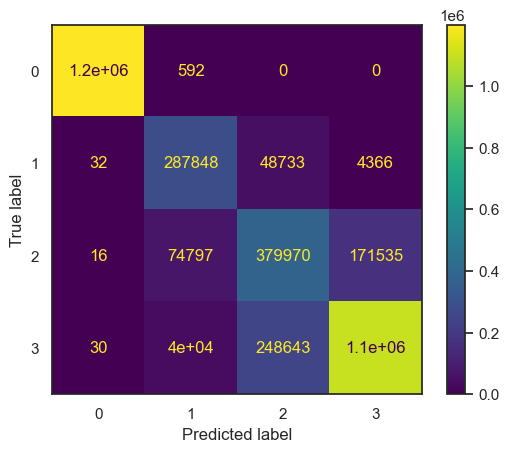

              precision    recall  f1-score   support

           0     0.9999    0.9995    0.9997   1199210
           1     0.7140    0.8442    0.7736    340979
           2     0.5610    0.6067    0.5829    626318
           3     0.8618    0.7918    0.8253   1385922

    accuracy                         0.8343   3552429
   macro avg     0.7842    0.8105    0.7954   3552429
weighted avg     0.8412    0.8343    0.8365   3552429



In [ ]:
model_tcn_mhal = load_model("Saved_Models/TCN_model_MHAL_OS.keras")

sns.set_theme(style="white")
# evaluates the model and plots the confusion matrix
predictions_tcn_mhal = model_tcn_mhal.predict(X_test_t)

y_pred_tcn_mhal = np.argmax(predictions_tcn_mhal, axis=1) 
    
final_preds_tcn_mhal = y_pred_tcn_mhal


y_true_labels_tcn_mhal = np.argmax(Y_test_t, axis=1)
ConfusionMatrixDisplay.from_predictions(y_true_labels_tcn_mhal, final_preds_tcn_mhal)
plt.show()

report_fcn_tcn_mhal = classification_report(y_true_labels_tcn_mhal, final_preds_tcn_mhal, digits=4)
print(report_fcn_tcn_mhal)

## Ensemble Stacking 

In [ ]:
RF_true = load("Outputs/y_true_RF.joblib")
RF_proba = flatten(load("Outputs/y_pred_prob_RF.joblib"))

LightGBM_true = load("Outputs/y_true_LBG1.joblib")
LightGBM_proba = flatten(load("Outputs/y_pred_prob_LBG1.joblib"))

TCN_true = load("Outputs/y_true_TCN.joblib")
TCN_proba = flatten(load("Outputs/y_pred_prob_TCN.joblib"))

TCN_MHAL_true = load("Outputs/y_true_TCN_MH.joblib")
TCN_MHAL_proba = flatten(load("Outputs/y_pred_prob_TCN_MH.joblib"))

GAT_true = load("Outputs/y_true_GAT.joblib")
GAT_proba = flatten(load("Outputs/y_pred_prob_GAT.joblib"))

In [ ]:
seed_value= 42  
os.environ['PYTHONHASHSEED']=str(seed_value)
random.seed(seed_value)
np.random.seed(seed_value)
tf.compat.v1.set_random_seed(seed_value)

X_meta_val_LGBM_TCN_TMHAL = np.hstack([LightGBM_proba, TCN_proba, TCN_MHAL_proba])  
meta_LGBM_TCN_TMHAL = LogisticRegression(solver="lbfgs", max_iter=500,  C=1.0,class_weight="balanced", random_state =42)
meta_LGBM_TCN_TMHAL .fit(X_meta_val_LGBM_TCN_TMHAL, flatten(RF_true))

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:

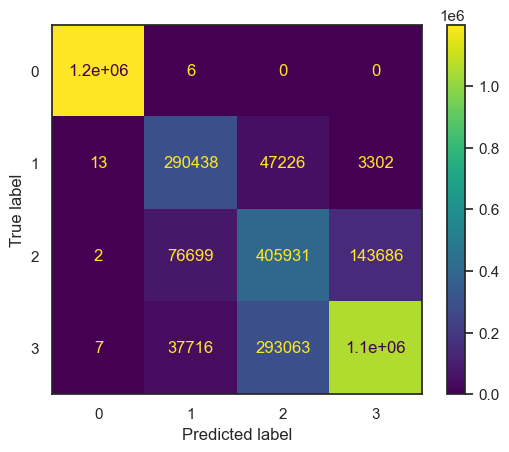

              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000   1199210
           1     0.7174    0.8518    0.7788    340979
           2     0.5440    0.6481    0.5915    626318
           3     0.8777    0.7613    0.8154   1385922

    accuracy                         0.8306   3552429
   macro avg     0.7848    0.8153    0.7964   3552429
weighted avg     0.8448    0.8306    0.8347   3552429



In [ ]:
seed_value= 42  
os.environ['PYTHONHASHSEED']=str(seed_value)
random.seed(seed_value)
np.random.seed(seed_value)
tf.compat.v1.set_random_seed(seed_value)

X_meta_test_LGBM_TCN_TMHAL = np.hstack([y_pred_prob_lbgm, predictions_tcn, predictions_tcn_mhal])  
P_ens_test_LGBM_TCN_TMHAL = meta_LGBM_TCN_TMHAL.predict_proba(X_meta_test_LGBM_TCN_TMHAL)
y_pred_LGBM_TCN_TMHAL = P_ens_test_LGBM_TCN_TMHAL.argmax(axis=1)

y_true_labels_LGBM_TCN_TMHAL = np.argmax(Y_test_t, axis=1)
ConfusionMatrixDisplay.from_predictions(y_true_labels_LGBM_TCN_TMHAL,y_pred_LGBM_TCN_TMHAL)
plt.show()

report_fcn_LGBM_TCN_TMHAL = classification_report(y_true_labels_LGBM_TCN_TMHAL, y_pred_LGBM_TCN_TMHAL, digits=4)
print(report_fcn_LGBM_TCN_TMHAL)

In [ ]:
y_pred_prob_LGBM_TCN_TMHAL = np.asarray(P_ens_test_LGBM_TCN_TMHAL)
y_pred_labels_LGBM_TCN_TMHAL = np.asarray(y_pred_LGBM_TCN_TMHAL)

# SHAP Analysis

## Meta-Stacking

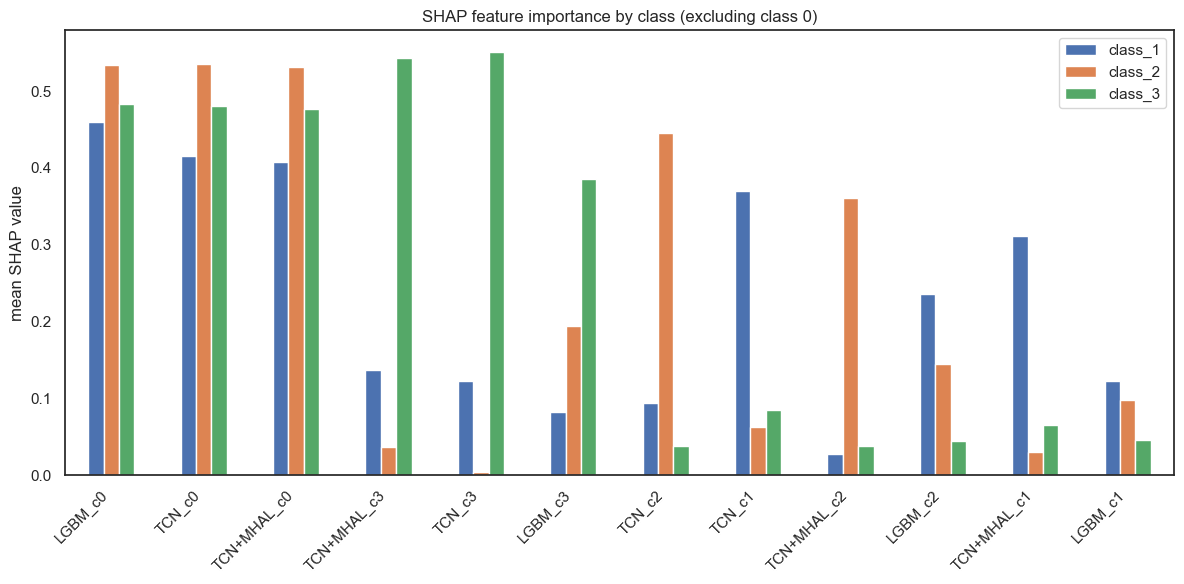

In [ ]:
def proba_df(name, proba):
    proba = np.asarray(proba)
    return pd.DataFrame(proba, columns=[f"{name}_c{k}" for k in range(proba.shape[1])])

X_meta_LGBM_TCN_TMHAL = pd.concat([
    proba_df("LGBM", y_pred_prob_lbgm), 
    proba_df("TCN", predictions_tcn),
    proba_df("TCN+MHAL", predictions_tcn_mhal)
], axis=1)


# X_meta: columns = base models' OOF predicted probabilities 
explainer = shap.LinearExplainer(meta_LGBM_TCN_TMHAL, X_meta_LGBM_TCN_TMHAL)

shap_values = explainer.shap_values(X_meta_LGBM_TCN_TMHAL)

# global importance per base model
importance = np.mean(np.abs(shap_values), axis=0)

sv = shap_values       
X = X_meta_LGBM_TCN_TMHAL              

ignore_class = 0          
top_k = 20             

classes = list(range(sv.shape[2]))
if ignore_class is not None:
    classes = [c for c in classes if c != ignore_class]

# mean absolute shap per feature per class 
imp = np.mean(np.abs(sv[:, :, classes]), axis=0)

df = pd.DataFrame(
    imp,
    index=X.columns,
    columns=[f"class_{c}" for c in classes]
)

# pick top features by average importance across plotted classes
top_features = df.mean(axis=1).sort_values(ascending=False).head(top_k).index
df_top = df.loc[top_features]

# plot grouped bars 
ax = df_top.plot(kind="bar", figsize=(12, 6))
ax.set_ylabel("mean SHAP value")
ax.set_title("SHAP feature importance by class" + (f" (excluding class {ignore_class})" if ignore_class is not None else ""))
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

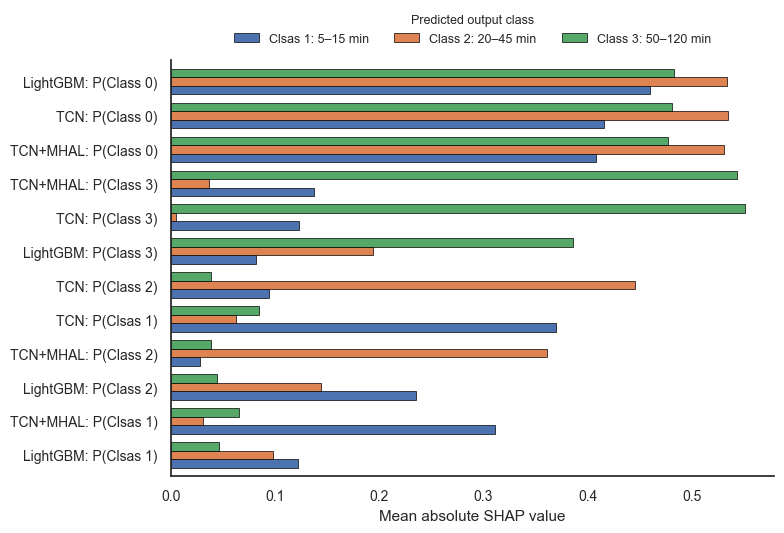

In [ ]:
class_intervals = {
    0: "Class 0: 0 min",
    1: "Clsas 1: 5–15 min",
    2: "Class 2: 20–45 min",
    3: "Class 3: 50–120 min"
}

class_intervals_label = {
    0: "Class 0",
    1: "Clsas 1",
    2: "Class 2",
    3: "Class 3"
}

def format_feature(name):
    model, cls = name.rsplit("_c", 1)
    model = {"LGBM": "LightGBM"}.get(model, model)
    return f"{model}: P({class_intervals_label[int(cls)]})"

# Reverse order so the most important features appear at the top
df_plot = df_top.iloc[::-1].copy()

df_plot.index = [format_feature(f) for f in df_plot.index]

# Rename legend entries
df_plot.columns = [
    class_intervals[int(c.split("_")[1])]
    for c in df_plot.columns
]

# Horizontal grouped bar plot
fig, ax = plt.subplots(figsize=(8, 5.5))

df_plot.plot(
    kind="barh",
    ax=ax,
    width=0.75,
    edgecolor="black",
    linewidth=0.5
)

ax.set_xlabel("Mean absolute SHAP value", fontsize=11)
ax.set_ylabel("")

ax.tick_params(axis="x", labelsize=10)
ax.tick_params(axis="y", labelsize=10)

ax.legend(
    title="Predicted output class",
    fontsize=9,
    title_fontsize=9,
    frameon=False,
    loc="lower center",
    bbox_to_anchor=(0.5, 1.01),
    ncol=3
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.savefig(
    "Plots/SHAP_meta_stacking.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

## LightGBM

In [ ]:
seed_value= 42  
os.environ["PYTHONHASHSEED"]=str(seed_value)
random.seed(seed_value)
np.random.seed(seed_value)
tf.compat.v1.set_random_seed(seed_value)

# Create the SHAP explainer for the Random Forest model
explainer_lbgm = shap.TreeExplainer(model_lbgm)
X_test_df = pd.DataFrame(X_test_feat_all, columns=a)
X_test_df = pd.DataFrame(X_test_feat_all, columns=a)
X_ex = X_test_df.sample(frac=0.01, random_state=42)
X = X_ex
shap_values_lbgm = explainer_lbgm.shap_values(X)


In [ ]:
# Handle SHAP versions that return one array per class
if isinstance(shap_values_lbgm, list):
    sv = np.stack(shap_values_lbgm, axis=-1)
else:
    sv = np.asarray(shap_values_lbgm)

# Expected shape: (n_samples, n_features, 4)
print("SHAP values shape:", sv.shape)


# Select classes and features
ignore_class = 0
top_k = 10

classes = list(range(sv.shape[2]))
if ignore_class is not None:
    classes = [c for c in classes if c != ignore_class]

imp = np.mean(np.abs(sv[:, :, classes]), axis=0)

df = pd.DataFrame(
    imp,
    index=X.columns,
    columns=[f"class_{c}" for c in classes]
)

SHAP values shape: (35524, 83, 4)


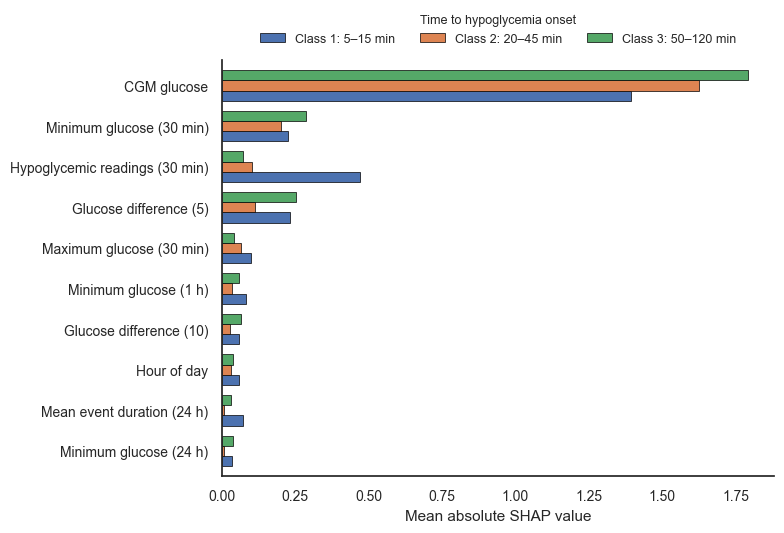

In [ ]:
df2 = pd.DataFrame(
    imp,
    index=X.columns,
    columns=[f"class_{c}" for c in classes]
)

top_features2 = df2.mean(axis=1).sort_values(
    ascending=False
).head(top_k).index

df_top2 = df2.loc[top_features2]

feature_labels2 = {
    "GlucoseCGM": "CGM glucose",
    "diff_5": "Glucose difference (5)",
    "diff_10": "Glucose difference (10)",
    "diff_20": "Glucose difference (20)",
    "diff_40": "Glucose difference (40)",

    "GlucoseCGM_mean_30min": "Mean glucose (30 min)",
    "GlucoseCGM_std_30min": "Glucose SD (30 min)",
    "GlucoseCGM_min_30min": "Minimum glucose (30 min)",
    "GlucoseCGM_max_30min": "Maximum glucose (30 min)",
    "n_30min": "Number of readings (30 min)",
    "time_below70_30min": "Time below 70 mg/dL (30 min)",
    "time_above200_30min": "Time above 200 mg/dL (30 min)",
    "diff_30min": "Glucose difference (30 min)",
    "slope_30min": "Glucose slope (30 min)",

    "GlucoseCGM_mean_1hr": "Mean glucose (1 h)",
    "GlucoseCGM_std_1hr": "Glucose SD (1 h)",
    "GlucoseCGM_min_1hr": "Minimum glucose (1 h)",
    "GlucoseCGM_max_1hr": "Maximum glucose (1 h)",
    "n_1hr": "Number of readings (1 h)",
    "time_below70_1hr": "Time below 70 mg/dL (1 h)",
    "time_above200_1hr": "Time above 200 mg/dL (1 h)",
    "diff_1hr": "Glucose difference (1 h)",
    "slope_1hr": "Glucose slope (1 h)",

    "GlucoseCGM_mean_2hr": "Mean glucose (2 h)",
    "GlucoseCGM_std_2hr": "Glucose SD (2 h)",
    "GlucoseCGM_min_2hr": "Minimum glucose (2 h)",
    "GlucoseCGM_max_2hr": "Maximum glucose (2 h)",
    "n_2hr": "Number of readings (2 h)",
    "time_below70_2hr": "Time below 70 mg/dL (2 h)",
    "time_above200_2hr": "Time above 200 mg/dL (2 h)",
    "diff_2hr": "Glucose difference (2 h)",
    "slope_2hr": "Glucose slope (2 h)",

    "GlucoseCGM_mean_4hr": "Mean glucose (4 h)",
    "GlucoseCGM_std_4hr": "Glucose SD (4 h)",
    "GlucoseCGM_min_4hr": "Minimum glucose (4 h)",
    "GlucoseCGM_max_4hr": "Maximum glucose (4 h)",
    "n_4hr": "Number of readings (4 h)",
    "time_below70_4hr": "Time below 70 mg/dL (4 h)",
    "time_above200_4hr": "Time above 200 mg/dL (4 h)",
    "diff_4hr": "Glucose difference (4 h)",
    "slope_4hr": "Glucose slope (4 h)",

    "GlucoseCGM_mean_8hr": "Mean glucose (8 h)",
    "GlucoseCGM_std_8hr": "Glucose SD (8 h)",
    "GlucoseCGM_min_8hr": "Minimum glucose (8 h)",
    "GlucoseCGM_max_8hr": "Maximum glucose (8 h)",
    "n_8hr": "Number of readings (8 h)",
    "time_below70_8hr": "Time below 70 mg/dL (8 h)",
    "time_above200_8hr": "Time above 200 mg/dL (8 h)",
    "diff_8hr": "Glucose difference (8 h)",
    "slope_8hr": "Glucose slope (8 h)",

    "GlucoseCGM_mean_24hr": "Mean glucose (24 h)",
    "GlucoseCGM_std_24hr": "Glucose SD (24 h)",
    "GlucoseCGM_min_24hr": "Minimum glucose (24 h)",
    "GlucoseCGM_max_24hr": "Maximum glucose (24 h)",
    "n_24hr": "Number of readings (24 h)",
    "time_below70_24hr": "Time below 70 mg/dL (24 h)",
    "time_above200_24hr": "Time above 200 mg/dL (24 h)",
    "diff_24hr": "Glucose difference (24 h)",
    "slope_24hr": "Glucose slope (24 h)",

    "hypo_points_30m": "Hypoglycemic readings (30 min)",
    "avg_event_duration_min_30m": "Mean event duration (30 min)",
    "min_since_last_event_30m": "Time since last event (30 min)",

    "hypo_points_1h": "Hypoglycemic readings (1 h)",
    "avg_event_duration_min_1h": "Mean event duration (1 h)",
    "min_since_last_event_1h": "Time since last event (1 h)",

    "hypo_points_2h": "Hypoglycemic readings (2 h)",
    "avg_event_duration_min_2h": "Mean event duration (2 h)",
    "min_since_last_event_2h": "Time since last event (2 h)",

    "hypo_points_4h": "Hypoglycemic readings (4 h)",
    "avg_event_duration_min_4h": "Mean event duration (4 h)",
    "min_since_last_event_4h": "Time since last event (4 h)",

    "hypo_points_24h": "Hypoglycemic readings (24 h)",
    "avg_event_duration_min_24h": "Mean event duration (24 h)",
    "min_since_last_event_24h": "Time since last event (24 h)",

    "hour": "Hour of day",
    "minute": "Minute of hour",
    "dayofweek": "Day of week",

    "valid_30min": "Valid data (30 min)",
    "valid_1hr": "Valid data (1 h)",
    "valid_2hr": "Valid data (2 h)",
    "valid_4hr": "Valid data (4 h)",
    "valid_8hr": "Valid data (8 h)",
    "valid_24hr": "Valid data (24 h)"
}

class_intervals2 = {
    0: "Class 0: 0 min",
    1: "Class 1: 5–15 min",
    2: "Class 2: 20–45 min",
    3: "Class 3: 50–120 min"
}

df_plot2 = df_top2.iloc[::-1].copy()

df_plot2.index = [
    feature_labels2.get(f, f.replace("_", " "))
    for f in df_plot2.index
]

df_plot2.columns = [
    class_intervals2[int(c.split("_")[1])]
    for c in df_plot2.columns
]


# 5. Horizontal grouped bars with black outlines
fig2, ax2 = plt.subplots(figsize=(8, 5.5))

df_plot2.plot(
    kind="barh",
    ax=ax2,
    width=0.75,
    edgecolor="black",
    linewidth=0.5
)

ax2.set_xlabel("Mean absolute SHAP value", fontsize=11)
ax2.set_ylabel("")

ax2.tick_params(axis="x", labelsize=10)
ax2.tick_params(axis="y", labelsize=10)

ax2.legend(
    title="Time to hypoglycemia onset",
    fontsize=9,
    title_fontsize=9,
    frameon=False,
    loc="lower center",
    bbox_to_anchor=(0.5, 1.01),
    ncol=3
)

ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)

plt.tight_layout()

# 6. Save for journal publication
plt.savefig(
    "SHAP_LGBM.pdf",
    bbox_inches="tight"
)

plt.savefig(
    "SHAP_LGBM.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

# Misclassification Analysis

In [ ]:
def build_pred_time_matrix_polars(y_pred, y_true, minutes):

    df = pl.DataFrame({
        "y_pred":  y_pred.astype(np.int8),
        "y_true":  y_true.astype(np.int8),
        "minutes": minutes.astype(np.float32),
    })

    # Bin assignment  
    df = df.with_columns(
        pl.col("minutes")
          .floordiv(5)
          .clip(0, 24)
          .cast(pl.Int8)
          .alias("bin")
    )

    # Group-by count
    counts = (
        df.group_by(["y_pred", "bin"])
          .agg(pl.len().alias("count"))
          .sort(["y_pred", "bin"])
    )

    # dense (4, 25) matrix
    matrix = np.zeros((4, 25), dtype=np.int32)
    for row in counts.iter_rows():
        pred_cls, bin_idx, count = row
        if 0 <= pred_cls <= 3 and 0 <= bin_idx <= 24:
            matrix[pred_cls, bin_idx] = count

    return matrix, df  

In [104]:
def build_temporal_confusion_polars(df):
    """
    df: Polars DataFrame with columns y_pred, y_true, bin
    Returns a dict (true_cls, pred_cls) -> (25,) count array
    """
    counts = (
        df.filter(pl.col("y_pred") != pl.col("y_true"))   # misclassified only
          .group_by(["y_true", "y_pred", "bin"])
          .agg(pl.len().alias("count"))
          .sort(["y_true", "y_pred", "bin"])
    )

    result = {}
    for (tc, pc) in [(t, p) for t in range(4) for p in range(4) if t != p]:
        subset = (
            counts
            .filter((pl.col("y_true") == tc) & (pl.col("y_pred") == pc))
        )
        arr = np.zeros(25, dtype=np.int32)
        for row in subset.iter_rows():
            _, _, b, c = row
            if 0 <= b <= 24:
                arr[b] = c
        result[(tc, pc)] = arr

    return result

In [ ]:
def build_temporal_error_rates_polars(df):
    """
    Returns dict (tc, pc) -> (25,) float rate array
    """
    # Total per (true_class, bin)
    totals = (
        df.group_by(["y_true", "bin"])
          .agg(pl.len().alias("total"))
    )

    # Misclassified per (true, pred, bin)
    errors = (
        df.filter(pl.col("y_pred") != pl.col("y_true"))
          .group_by(["y_true", "y_pred", "bin"])
          .agg(pl.len().alias("errors"))
    )

    # Join and compute rate  
    rates_df = (
        errors
        .join(totals, on=["y_true", "bin"], how="left")
        .with_columns(
            (pl.col("errors") / pl.col("total")).alias("rate")
        )
        .sort(["y_true", "y_pred", "bin"])
    )

    result = {}
    for (tc, pc) in [(t, p) for t in range(4) for p in range(4) if t != p]:
        subset = rates_df.filter(
            (pl.col("y_true") == tc) & (pl.col("y_pred") == pc)
        )
        arr = np.full(25, np.nan, dtype=np.float32)
        for row in subset.iter_rows():
            _, _, b, _, _, rate = row
            if 0 <= b <= 24:
                arr[b] = rate
        result[(tc, pc)] = arr

    return result

In [ ]:
matrix, df_pl = build_pred_time_matrix_polars(y_pred_labels_LGBM_TCN_TMHAL, flatten(Y_test_fold), flatten(Y_exact))

temporal_conf  = build_temporal_confusion_polars(df_pl)
temporal_rates = build_temporal_error_rates_polars(df_pl)

print("Matrix shape:", matrix.shape)
print("Total predictions:", matrix.sum())
print(f"Memory used by df: {df_pl.estimated_size('mb'):.1f} MB")

Matrix shape: (4, 25)
Total predictions: 3552429
Memory used by df: 23.7 MB


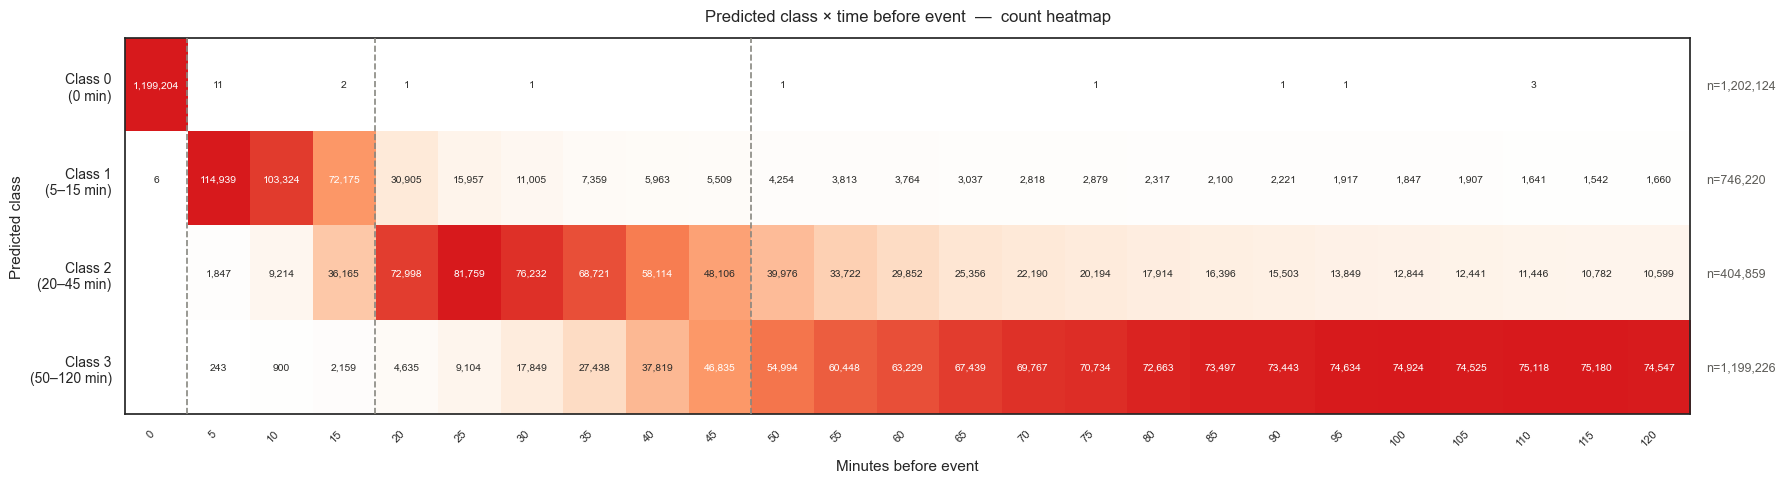

In [ ]:
def plot_heatmap(matrix):
    cmap = LinearSegmentedColormap.from_list(
        "count_map", ["#ffffff", "#FEE5D0", "#FC8D59", "#D7191C"]
    )
    CLASS_NAMES  = ["Class 0\n(0 min)", "Class 1\n(5–15 min)",
                "Class 2\n(20–45 min)", "Class 3\n(50–120 min)"]
    BIN_LABELS    = [str(t) for t in np.arange(0, 125, 5)]   # 0,5,...,120
    BOUNDARY_BINS = [1, 4, 10]
    N_BINS        = 25

    fig, ax = plt.subplots(figsize=(18, 5))

    # per-row normalisation
    im_data = np.zeros_like(matrix, dtype=float)
    for cls in range(4):
        row_max = matrix[cls].max()
        if row_max > 0:
            im_data[cls] = matrix[cls] / row_max

    # imshow: explicitly set extent so cells are centered on 0..24
    ax.imshow(im_data, aspect="auto", cmap=cmap,
              vmin=0, vmax=1, interpolation="nearest",
              extent=[-0.5, N_BINS - 0.5, 3.5, -0.5])   # fix 1: explicit extent

    # boundary dashed lines
    for b in BOUNDARY_BINS:
        ax.axvline(b - 0.5, color="#888780",
                   linewidth=1.2, linestyle="--", zorder=3)

    # cell text
    row_totals = matrix.sum(axis=1)
    for cls in range(4):
        for b in range(N_BINS):
            val = matrix[cls, b]
            if val == 0:
                continue
            text_color = "white" if im_data[cls, b] > 0.6 else "#2C2C2A"
            ax.text(b, cls, f"{val:,}",
                    ha="center", va="center",
                    fontsize=7.5, color=text_color,
                    fontweight="500", zorder=3)

    ax.set_xlim(-0.5, N_BINS - 0.5)
    ax.set_ylim(3.5, -0.5)

    # n= totals using figure transform so they never overlap the heatmap
    for cls in range(4):
        ax.annotate(
            f"n={row_totals[cls]:,}",
            xy=(1.01, (cls + 0.5) / 4),          # axes-fraction coordinates
            xycoords="axes fraction",
            fontsize=9, color="#5F5E5A",
            va="center", ha="left"
        )

    ax.set_xticks(range(N_BINS))
    ax.set_xticklabels(BIN_LABELS, fontsize=8, rotation=45, ha="right")
    ax.set_yticks(range(4))
    ax.set_yticklabels(CLASS_NAMES, fontsize=10)
    ax.set_xlabel("Minutes before event", fontsize=11, labelpad=8)
    ax.set_ylabel("Predicted class", fontsize=11)

    # colorbar
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(0, 1))
    sm.set_array([])

    ax.set_title("Predicted class × time before event  —  count heatmap",
                 fontsize=12, pad=12)

    plt.tight_layout()
    plt.savefig("temporal_pred_heatmap.png", dpi=150, bbox_inches="tight")
    plt.show()

plot_heatmap(matrix)

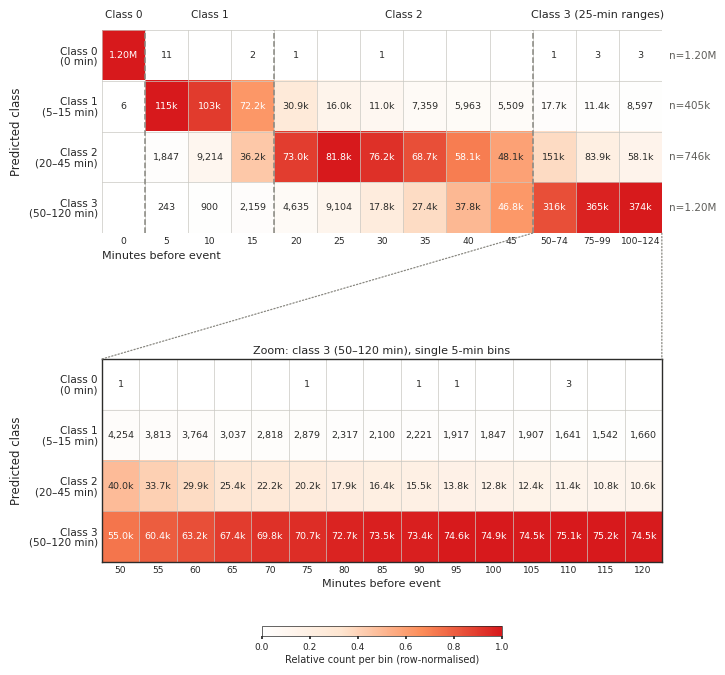

In [117]:
plt.rcParams.update({
    "pdf.fonttype": 42, "svg.fonttype": "none",   # real text in vector files
    "font.family": "DejaVu Sans",
})
 
CMAP = LinearSegmentedColormap.from_list(
    "count_map", ["#ffffff", "#FEE5D0", "#FC8D59", "#D7191C"]
)
CLASS_NAMES   = ["Class 0\n(0 min)", "Class 1\n(5–15 min)",
                 "Class 2\n(20–45 min)", "Class 3\n(50–120 min)"]
BIN_MINUTES   = 5            # width of one original bin
N_BINS        = 25           # 0, 5, ..., 120
BOUNDARY_BINS = [1, 4, 10]   # first bin of class 1, 2, 3
GROUP         = 5            # class 3 in overview: bins merged per column (5 -> 25-min ranges)
ACCENT        = "#2C2C2A"
 
 
def fmt(v, compact=True):
    """Exact below 10,000; 30.9k / 115k / 1.20M above, so labels always fit a cell."""
    if not compact or v < 10_000:
        return f"{v:,}"
    if v < 100_000:
        return f"{v / 1e3:.1f}k"
    if v < 1_000_000:
        return f"{v / 1e3:.0f}k"
    return f"{v / 1e6:.2f}M"
 
 
def _label(lo, hi, two_line=True):
    if lo == hi:
        return str(lo * BIN_MINUTES)
    a, b = lo * BIN_MINUTES, hi * BIN_MINUTES + BIN_MINUTES - 1
    return f"{a}–\n{b}" if two_line else f"{a}–{b}"
 
 
def _draw(ax, counts, colour_vals, labels, fs_cell, fs_tick, fs_y):
    ncol = counts.shape[1]
    ax.imshow(colour_vals, aspect="auto", cmap=CMAP, vmin=0, vmax=1,
              interpolation="nearest", extent=[-0.5, ncol - 0.5, 3.5, -0.5])
    # thin white grid so single cells stay separable
    EDGE = "#C9C8C2"
    for x in np.arange(-0.5, ncol):
        ax.axvline(x, color=EDGE, lw=0.5, zorder=2)
    for y in np.arange(-0.5, 4):
        ax.axhline(y, color=EDGE, lw=0.5, zorder=2)
    for cls in range(4):
        for j in range(ncol):
            val = counts[cls, j]
            if val == 0:
                continue
            tc = "white" if colour_vals[cls, j] > 0.6 else ACCENT
            ax.text(j, cls, fmt(val), ha="center", va="center",
                    fontsize=fs_cell, color=tc, fontweight="medium", zorder=3)
    ax.set_xlim(-0.5, ncol - 0.5)
    ax.set_ylim(3.5, -0.5)
    ax.set_xticks(range(ncol))
    ax.set_xticklabels(labels, fontsize=fs_tick, linespacing=0.95)
    ax.set_yticks(range(4))
    ax.set_yticklabels(CLASS_NAMES, fontsize=fs_y, linespacing=1.0)
    ax.tick_params(length=0, pad=3)
    for s in ax.spines.values():
        s.set_visible(False)
 
 
def plot_heatmap(matrix, figsize=(8, 7), fs_cell=6.8, fs_tick=6.6, fs_y=7.5,
                 out="temporal_pred_heatmap", title=None):
    start = BOUNDARY_BINS[-1]
 
    row_max = matrix.max(axis=1, keepdims=True).astype(float)
    row_max[row_max == 0] = 1
    norm = matrix / row_max                              # per-row normalisation
 
    # overview: single bins up to class 3, then groups of GROUP bins
    spans = [(b, b) for b in range(start)]
    spans += [(b, min(b + GROUP - 1, N_BINS - 1)) for b in range(start, N_BINS, GROUP)]
    counts_ov = np.stack([matrix[:, lo:hi + 1].sum(axis=1) for lo, hi in spans], axis=1)
    colour_ov = np.stack([norm[:, lo:hi + 1].mean(axis=1) for lo, hi in spans], axis=1)
    labels_ov = [_label(lo, hi, two_line=False) for lo, hi in spans]
    n_ov = len(spans)
 
    counts_z = matrix[:, start:]
    colour_z = norm[:, start:]
    labels_z = [_label(b, b) for b in range(start, N_BINS)]
 
    fig = plt.figure(figsize=figsize)
    gs = fig.add_gridspec(2, 1, hspace=0.62, left=0.17, right=0.87,
                          top=0.91, bottom=0.15)
    ax1, ax2 = fig.add_subplot(gs[0]), fig.add_subplot(gs[1])
 
    # ---- overview -----------------------------------------------------------
    _draw(ax1, counts_ov, colour_ov, labels_ov, fs_cell, fs_tick, fs_y)
    for b in BOUNDARY_BINS:
        ax1.axvline(b - 0.5, color="#888780", lw=1.1, ls="--", zorder=4)
    edges = [-0.5] + [b - 0.5 for b in BOUNDARY_BINS] + [n_ov - 0.5]
    for i in range(4):
        head = f"Class {i}" + (f" ({GROUP * BIN_MINUTES}-min ranges)" if i == 3 else "")
        ax1.text((edges[i] + edges[i + 1]) / 2, -0.7, head, ha="center",
                 va="bottom", fontsize=7.5 if i < 3 else 8,
                 wrap=False)
    for cls, tot in enumerate(matrix.sum(axis=1)):
        ax1.text(1.012, cls, f"n={fmt(tot)}", transform=ax1.get_yaxis_transform(),
                 fontsize=7.5, color="#5F5E5A", va="center", ha="left")
    ax1.set_xlabel("Minutes before event", fontsize=8, labelpad=3, loc="left")
    ax1.set_ylabel("Predicted class", fontsize=8.5)
 
    # ---- zoom ---------------------------------------------------------------
    _draw(ax2, counts_z, colour_z, labels_z, fs_cell, fs_tick, fs_y)
    for s in ax2.spines.values():
        s.set_visible(True); s.set_edgecolor(ACCENT); s.set_linewidth(1.0)
    ax2.set_xlabel("Minutes before event", fontsize=8, labelpad=3)
    ax2.set_ylabel("Predicted class", fontsize=8.5)
    ax2.set_title("Zoom: class 3 (50–120 min), single 5-min bins",
                  fontsize=8, pad=4)
    for xa, xb in ((start - 0.5, -0.5), (n_ov - 0.5, counts_z.shape[1] - 0.5)):
        fig.add_artist(ConnectionPatch((xa, 3.5), (xb, -0.5), "data", "data",
                                       axesA=ax1, axesB=ax2,
                                       color="#888780", lw=0.9, ls=":"))
 
    # ---- colourbar ----------------------------------------------------------
    cax = fig.add_axes([0.37, 0.045, 0.30, 0.014])
    sm = plt.cm.ScalarMappable(cmap=CMAP, norm=plt.Normalize(0, 1)); sm.set_array([])
    cb = fig.colorbar(sm, cax=cax, orientation="horizontal")
    cb.set_label("Relative count per bin (row-normalised)", fontsize=7, labelpad=2)
    cb.ax.tick_params(labelsize=6.5, length=2)
    cb.outline.set_linewidth(0.5)
 
    if title:
        fig.suptitle(title, fontsize=9, y=0.985)
 
    fig.savefig(out + ".pdf", bbox_inches="tight", pad_inches=0.06)                      # vector: sharp at any zoom
    fig.savefig(out + ".svg", bbox_inches="tight", pad_inches=0.06)
    fig.savefig(out + ".png", dpi=400, bbox_inches="tight", pad_inches=0.06)
    plt.show()
plot_heatmap(matrix)